# Distribution of the Main Relevance Score, Overall and by Sector

| Item | Description |
|---|---|
| Goal | Two figures for the main relevance measure, the cosine similarity between a firm-level summary of 10-K Item 1s and the policy summary of legislator statements on consumer data privacy legislation. Figure 1 is the histogram of the firm scores over all sample firms. Figure 2 overlays the kernel density of the same scores for the information, manufacturing, and mining sectors, so that the reader sees which sector sits to the right or to the left. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3); the CRSP-Compustat link file `crsp_compustat_link.dta` in the source data folder for each firm's Compustat NAICS code. |
| Output | `output/T3.9.1/fig_distribution_policy_summary_firm_summary_cosine_all_firms.{png,svg,pdf}` and `output/T3.9.1/fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde.{png,svg,pdf}`. |
| Unit | A firm (gvkey) in the sample set by `SAMPLE`: all years (every fiscal year a firm filed, 1999 to 2025; 1,058 firms) or the three years (fiscal 2010, 2015, 2020; 841 firms). Figure 2 groups firms by their NAICS two-digit sector as in T3.9.3. |
| Measure | `MEASURE_ID`, T3.8.3's `summaries \| policy_summary \| firm_summary`: the cosine similarity between the embedding of the firm-level summary (one language-model paragraph condensing the firm's yearly summaries of its 10-K Item 1 sections, T3.7.4) and the embedding of the policy summary (one language-model summary of the legislator statements on Topic 68, consumer data privacy legislation, T3.5.5). |
| Wording | Every title, axis title, and legend entry spells out what is measured: the two texts compared, the sector with its NAICS code and firm count, and what a bar or a curve height is. Axis titles and legend entries are in title case at the user's request; the figure titles follow S3 title case. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and notes in Markdown below. Figure 1 has one series in GREY and no legend; Figure 2 has one palette color per sector and a legend below the X-title. Both figures share the X range of the sample. |

See `README.md` in the TEMP folder for the surrounding steps, `T3.8.3` for the measure, and the archived `T3.9.1 - Figure - Distribution of Relevance Scores` (in `archive`) for the histograms of every measure.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde


## Step 2. Define file locations, the measure, the sectors, and the wording

The titles, axis titles, and legend entries are built from two phrases that name the texts compared, so that every figure says the same thing in the same words. The X-title is the figure title's own words broken into two lines so that it fits the axis width.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.1"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
LINK_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/01_firm_id/crsp_compustat_link.dta"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
MEASURE_ID = "summaries | policy_summary | firm_summary"
N_BINS = 30
FOCUS_SECTORS = ["Information", "Manufacturing", "Mining, quarrying, and oil and gas extraction"]  # Figure 2, in legend order
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}

# Wording. The two texts compared, in title case, then the titles built from them.
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
FIGURE_TITLES = {
    1: f"Distribution of {SCORE_TITLE}",
    2: f"Kernel Density of {SCORE_TITLE} for Firms in the Information, Manufacturing, and Mining Sectors",
}
X_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE}\nand {POLICY_SUMMARY_TITLE}"  # the same words as the title, on two lines
Y_TITLES = {1: "Number of Firms in the Bin", 2: "Kernel Density of Firms Within Each Sector\n(Area Under Each Curve Equals One)"}
SECTOR_LEGEND = {  # sector -> legend words with the NAICS code; the firm count is appended when drawing
    "Information": "Information Sector (NAICS 51)",
    "Manufacturing": "Manufacturing Sector (NAICS 31 to 33)",
    "Mining, quarrying, and oil and gas extraction": "Mining, Quarrying, and Oil and Gas Extraction Sector (NAICS 21)",
}
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
FIGURE_NAMES = {1: "fig_distribution_policy_summary_firm_summary_cosine_all_firms", 2: "fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde"}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.1


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. Figure 1 draws its bars in GREY; in Figure 2 each sector takes one palette color with a solid line.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
LINE_WIDTH = 1.6
LEGEND_FONT_SIZE = 10
EXPORT_DPI = 300
SECTOR_COLORS = {"Information": RED, "Manufacturing": MIDNIGHT_BLUE, "Mining, quarrying, and oil and gas extraction": BLUE}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores and attach a NAICS sector to every firm

The wide table of T3.8.3, the chosen sample only; the sector comes from the link file exactly as in T3.9.3. The measure column must be present and complete, and every focus sector must exist in the sample. The X range of both figures is the range of the measure over all sample firms.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
assert MEASURE_ID in wide.columns, MEASURE_ID
assert wide[MEASURE_ID].notna().all(), f"{int(wide[MEASURE_ID].isna().sum())} firms without a score"

link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
wide["naics"] = wide["gvkey"].map(naics)
assert wide["naics"].notna().all(), f"{int(wide['naics'].isna().sum())} firms without a NAICS code"
wide["naics2"] = wide["naics"].str[:2]
assert wide["naics2"].isin(NAICS_SECTORS).all(), sorted(set(wide["naics2"]) - set(NAICS_SECTORS))
wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
sector_sizes = wide.groupby("sector").size()
assert set(FOCUS_SECTORS) <= set(sector_sizes.index), set(FOCUS_SECTORS) - set(sector_sizes.index)

all_values = wide[MEASURE_ID].to_numpy()
lower, upper = float(all_values.min()), float(all_values.max())
pad = (upper - lower) * 0.02
values_by_sector = {sector: wide.loc[wide["sector"].eq(sector), MEASURE_ID].to_numpy() for sector in FOCUS_SECTORS}
print(f"Firms in the {SAMPLE} sample: {len(wide):,}; score range {lower:.3f} to {upper:.3f}; median {np.median(all_values):.3f}")
display(pd.DataFrame({"firms": {sector: len(v) for sector, v in values_by_sector.items()},
                      "median": {sector: np.median(v) for sector, v in values_by_sector.items()}}).round(4))


Firms in the all_years sample: 1,058; score range 0.403 to 0.621; median 0.511


,firms,median
Information,113,0.5463
Manufacturing,420,0.5079
"Mining, quarrying, and oil and gas extraction",53,0.4652


## Step 5. Figure 1: histogram over all firms

Bars in GREY over bins of equal width spanning the sample range, no reference line, no text inside the plot. One series, so no legend; positions are measured after drawing so that the Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge, and the X-title must fit between the side margins.


In [5]:
edges = np.linspace(lower, upper, N_BINS + 1)

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.18)
axis.hist(all_values, bins=edges, color=GREY, edgecolor="white", linewidth=0.4, zorder=2)
axis.set_xlim(lower - pad, upper + pad)
axis.set_xlabel(X_TITLE)
axis.set_ylabel(Y_TITLES[1])
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.width <= figure.bbox.width - 2 * margin_pixels, f"X-title is {x_title_box.width / figure.dpi:.2f} inches wide"
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{FIGURE_NAMES[1]}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

notes_1 = (f"Each bar counts the firms of {SAMPLE_WORDS[SAMPLE]}, {len(wide):,} firms, whose score falls in the bin; {N_BINS} bins of equal width "
           f"from {lower:.3f} to {upper:.3f}, the range of the sample. The score is {SCORE_WORDS}. "
           f"The median is {np.median(all_values):.3f} and the quartiles are {np.percentile(all_values, 25):.3f} and {np.percentile(all_values, 75):.3f}.")
print(f"Figure 1: {FIGURE_NAMES[1]} ({len(all_values):,} firms; X-title {x_title_box.width / figure.dpi:.2f} inches wide)")


Figure 1: fig_distribution_policy_summary_firm_summary_cosine_all_firms (1,058 firms; X-title 5.46 inches wide)


## Step 6. Figure 2: kernel density by sector

One line per focus sector, a Gaussian kernel density with Scott's bandwidth evaluated over the sample range, so the area under each line is one and sectors of different size are comparable. No text inside the plot. The legend names each sector with its NAICS code and firm count and sits 0.5 cm above the bottom edge with the most columns that fit between the side margins; the X-title ends 0.5 cm above the legend and the Y-title starts 0.5 cm from the left edge.


In [6]:
grid = np.linspace(lower, upper, 400)

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.3)
legend_handles = []
for sector in FOCUS_SECTORS:
    values = values_by_sector[sector]
    assert len(np.unique(values)) > 1, f"{sector}: one distinct value, no kernel density"
    axis.plot(grid, gaussian_kde(values)(grid), color=SECTOR_COLORS[sector], linewidth=LINE_WIDTH, zorder=2)
    legend_handles.append(Line2D([], [], color=SECTOR_COLORS[sector], linewidth=LINE_WIDTH))
legend_labels = [f"{SECTOR_LEGEND[sector]}, {len(values_by_sector[sector]):,} Firms" for sector in FOCUS_SECTORS]
axis.set_xlim(lower - pad, upper + pad)
axis.set_ylim(bottom=0)
axis.set_xlabel(X_TITLE)
axis.set_ylabel(Y_TITLES[2])
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.width <= figure.bbox.width - 2 * margin_pixels, f"X-title is {x_title_box.width / figure.dpi:.2f} inches wide"
for n_columns in range(len(FOCUS_SECTORS), 0, -1):  # the most columns that fit within the side margins
    legend = figure.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT),
                           bbox_transform=figure.transFigure, ncol=n_columns, frameon=False, fontsize=LEGEND_FONT_SIZE, borderaxespad=0)
    figure.canvas.draw()
    if legend.get_window_extent(renderer).width <= figure.bbox.width - 2 * margin_pixels:
        break
    legend.remove()
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (legend.get_window_extent(renderer).y1 + margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
y_title_box = axis.yaxis.label.get_window_extent(renderer)
assert y_title_box.height <= figure.bbox.height - 2 * margin_pixels, f"Y-title is {y_title_box.height / figure.dpi:.2f} inches tall"
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{FIGURE_NAMES[2]}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

sector_words = "; ".join(f"{SECTOR_LEGEND[sector]}, {len(values_by_sector[sector]):,} firms, median {np.median(values_by_sector[sector]):.3f}" for sector in FOCUS_SECTORS)
notes_2 = (f"Each line is a Gaussian kernel density estimate with Scott's bandwidth of the scores of the firms in one sector, evaluated from {lower:.3f} to {upper:.3f}, "
           "the range of the sample. The height of a line at a score is the density of the sector's firms at that score, not a count: the area under each line "
           "equals one, so sectors with different numbers of firms are comparable, and a line that sits further to the right means that the sector's firms score higher. "
           f"Firms are those of {SAMPLE_WORDS[SAMPLE]}, {len(wide):,} firms, and the sector is the firm's Compustat NAICS code cut to two digits, "
           f"with codes 31 to 33 merged into manufacturing. The score is {SCORE_WORDS}. Sectors shown: {sector_words}.")
print(f"Figure 2: {FIGURE_NAMES[2]} ({sum(len(v) for v in values_by_sector.values()):,} firms, legend in {n_columns} columns)")


Figure 2: fig_distribution_policy_summary_firm_summary_cosine_information_manufacturing_mining_kde (586 firms, legend in 2 columns)


## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order.


**Figure 1. Distribution of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation**

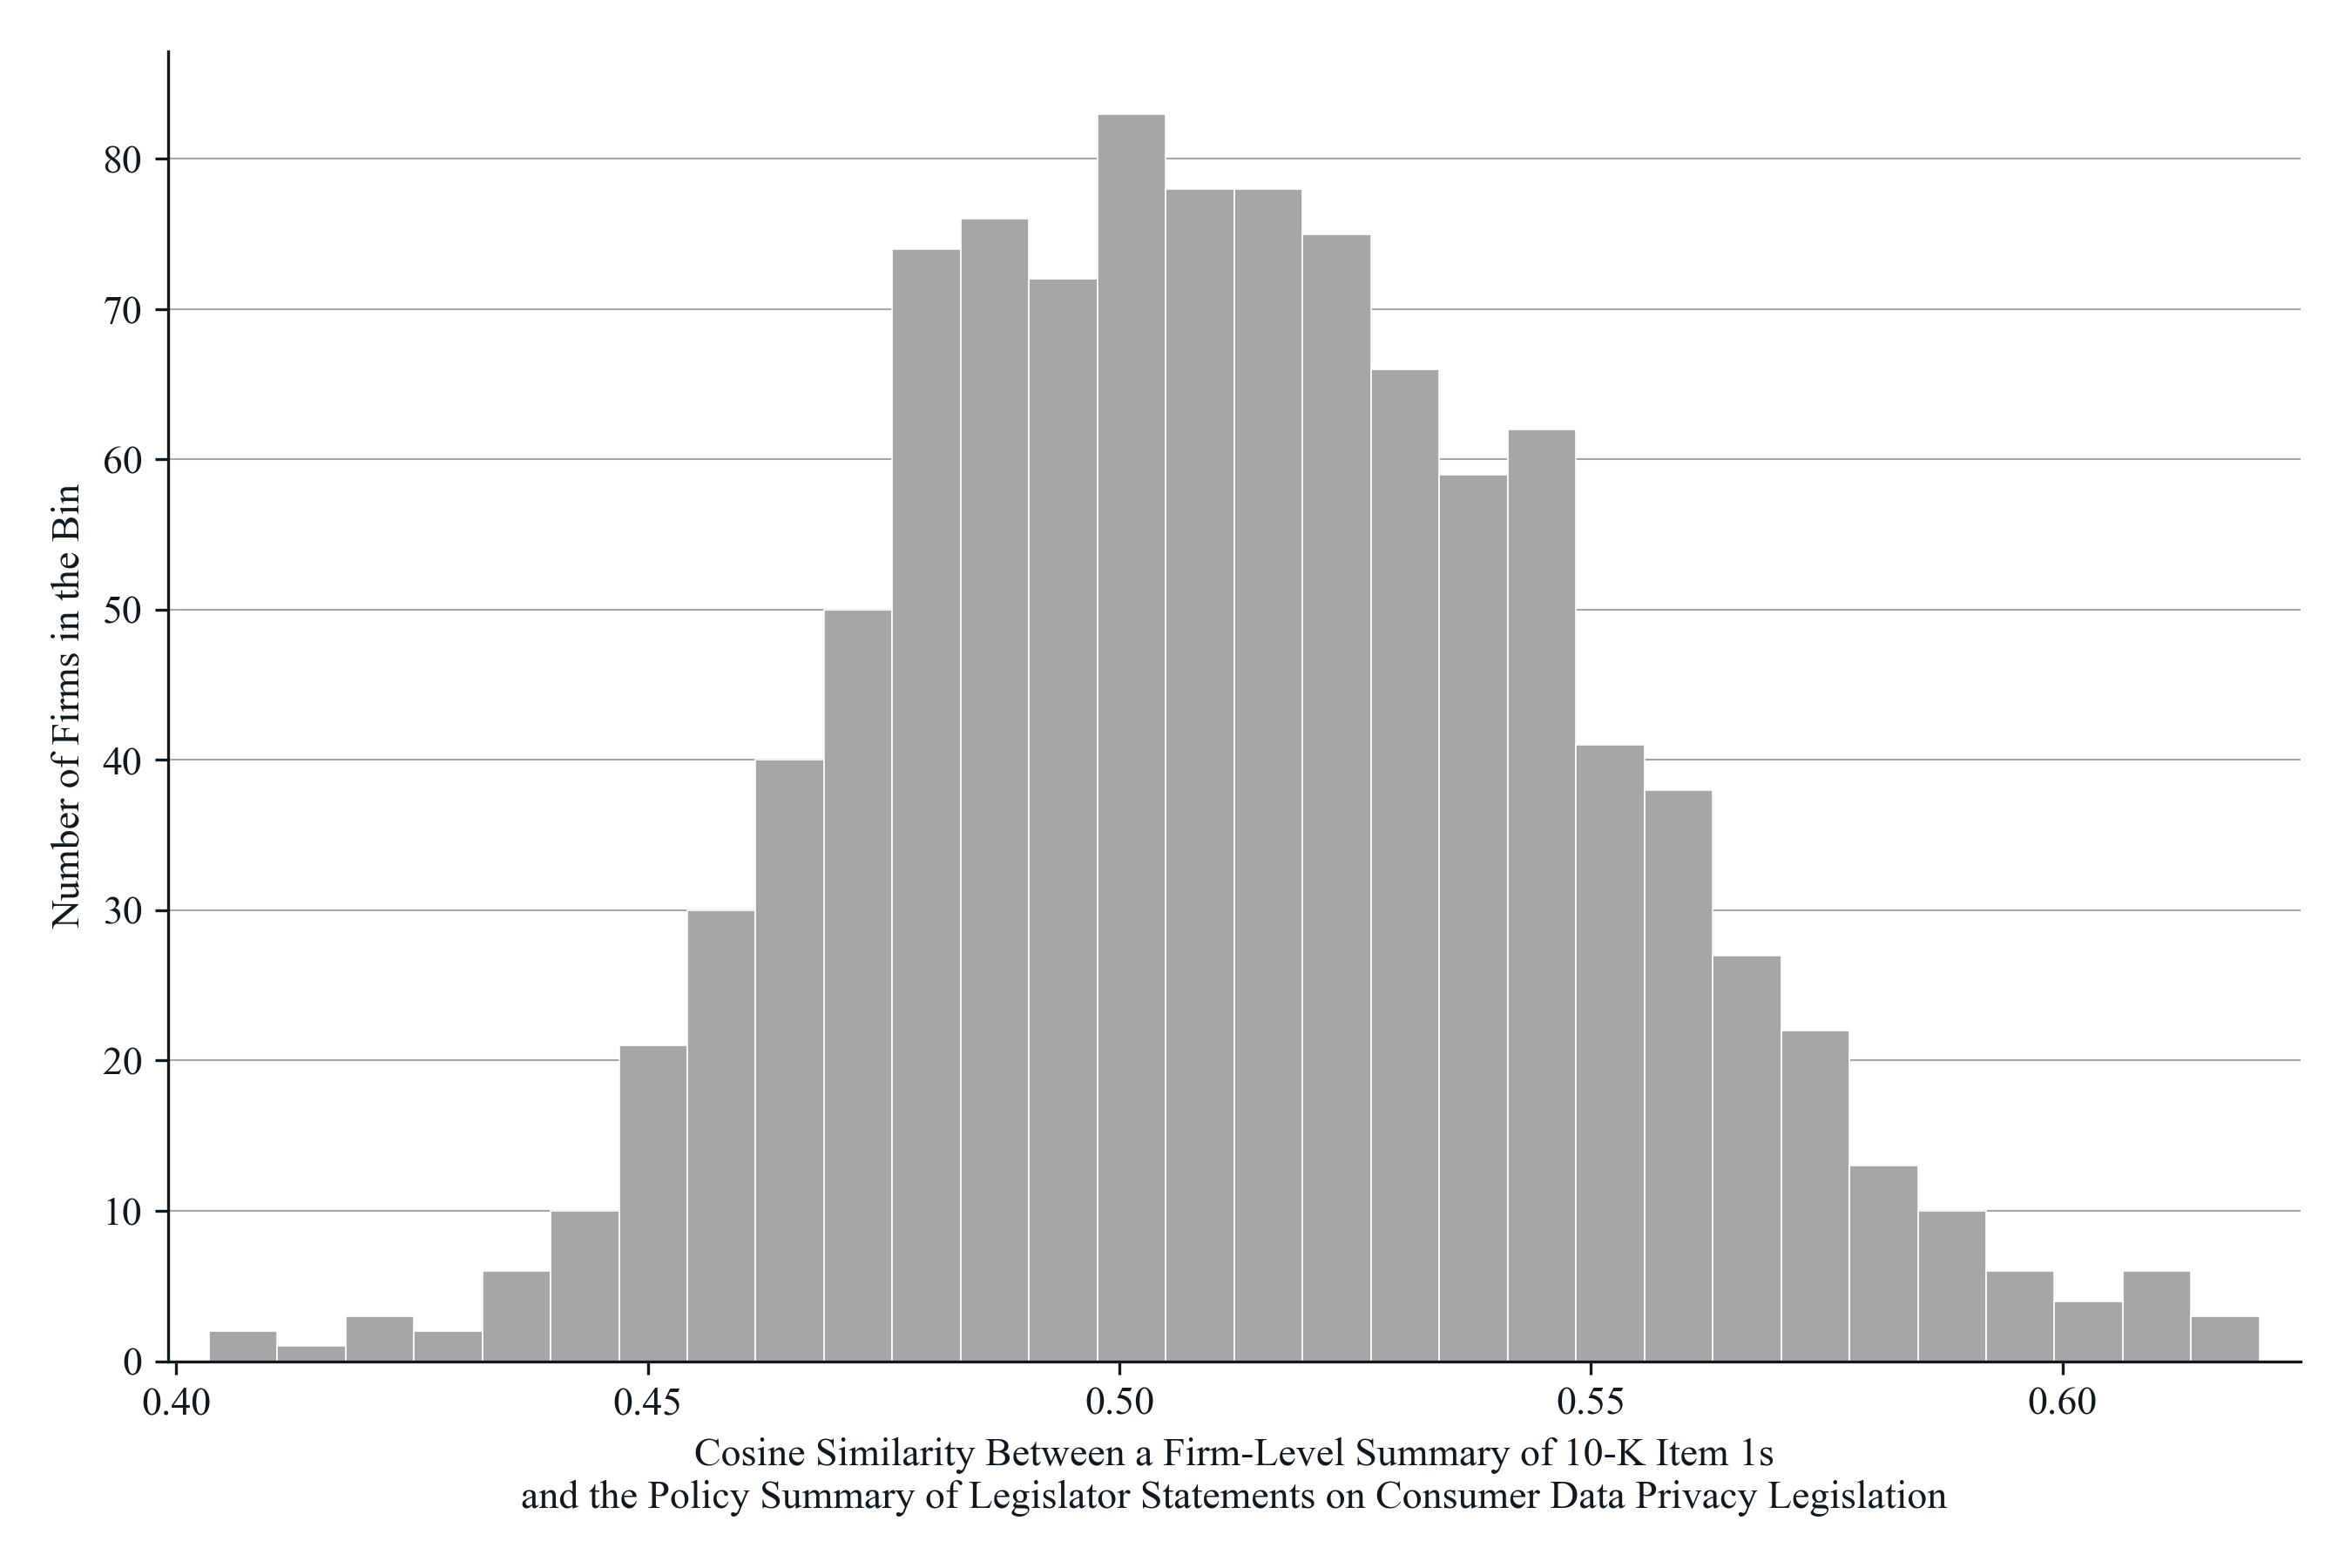

*Notes*: Each bar counts the firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 1,058 firms, whose score falls in the bin; 30 bins of equal width from 0.403 to 0.621, the range of the sample. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The median is 0.511 and the quartiles are 0.486 and 0.537.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Kernel Density of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation for Firms in the Information, Manufacturing, and Mining Sectors**

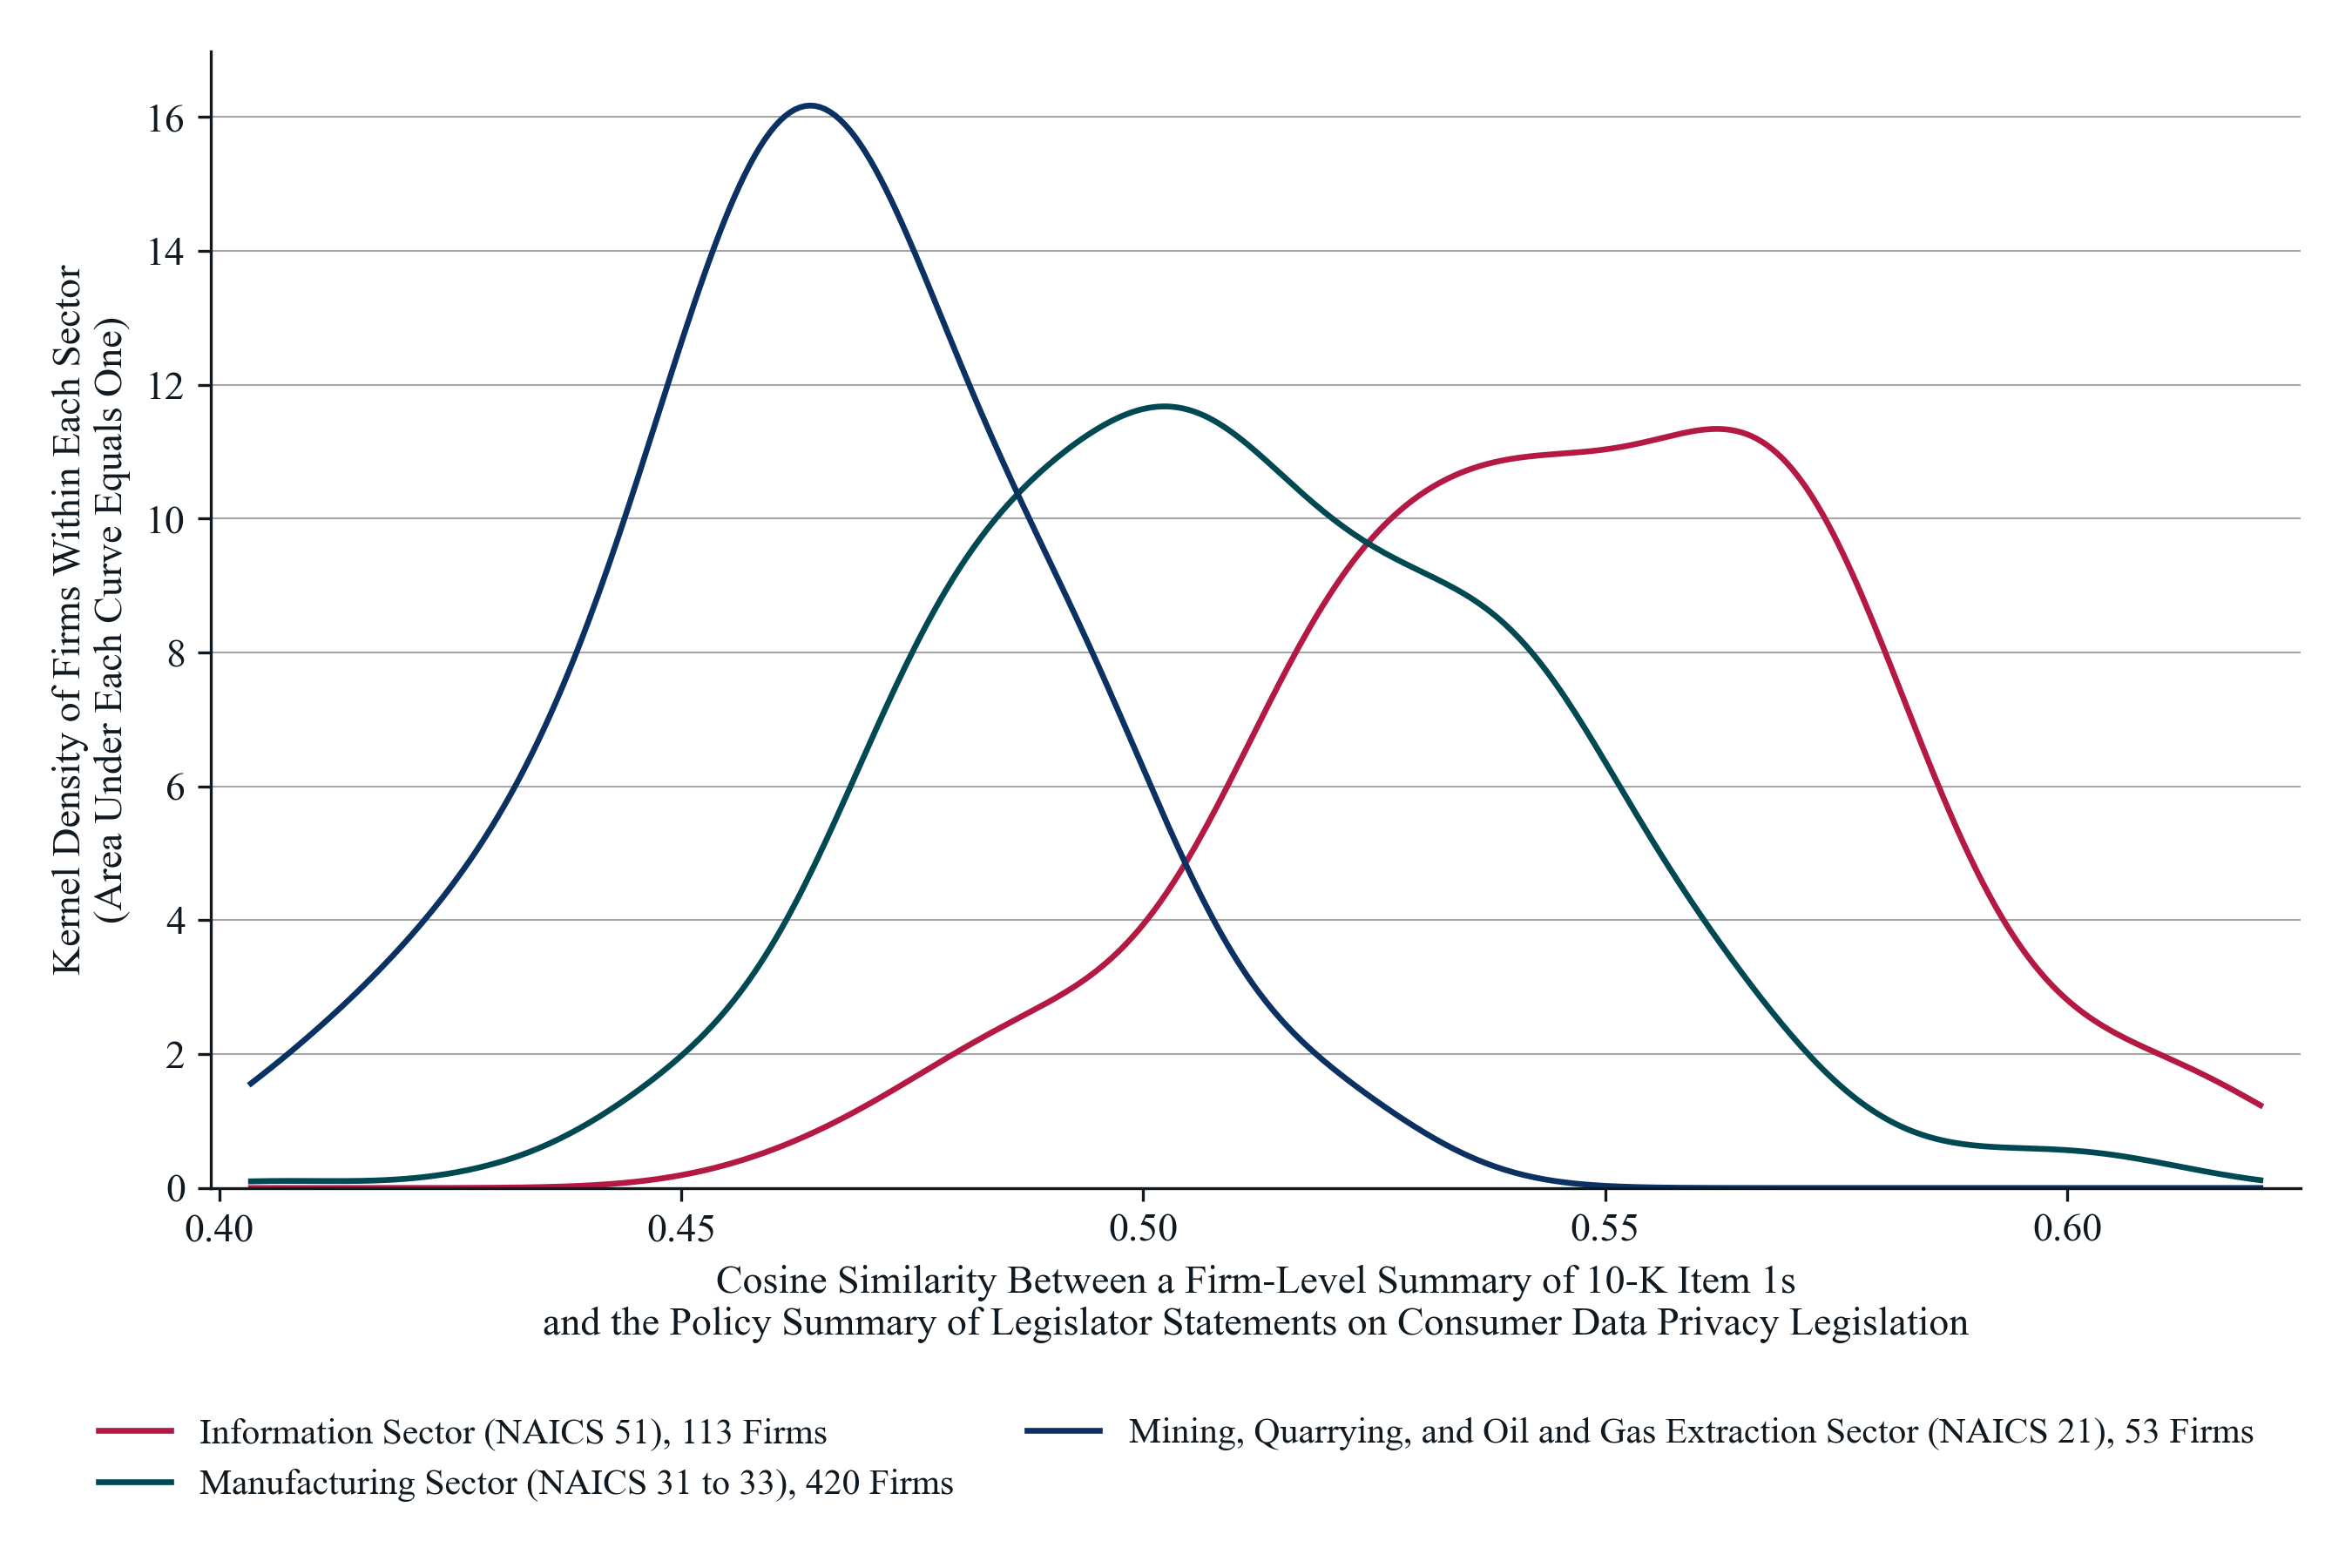

*Notes*: Each line is a Gaussian kernel density estimate with Scott's bandwidth of the scores of the firms in one sector, evaluated from 0.403 to 0.621, the range of the sample. The height of a line at a score is the density of the sector's firms at that score, not a count: the area under each line equals one, so sectors with different numbers of firms are comparable, and a line that sits further to the right means that the sector's firms score higher. Firms are those of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 1,058 firms, and the sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. Sectors shown: Information Sector (NAICS 51), 113 firms, median 0.546; Manufacturing Sector (NAICS 31 to 33), 420 firms, median 0.508; Mining, Quarrying, and Oil and Gas Extraction Sector (NAICS 21), 53 firms, median 0.465.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
for figure_number in [1, 2]:
    display(Markdown(f"**Figure {figure_number}. {FIGURE_TITLES[figure_number]}**"))
    display(Image(filename=str(OUTPUT_FOLDER / f"{FIGURE_NAMES[figure_number]}.png"), width=900))
    display(Markdown(f"*Notes*: {notes_1 if figure_number == 1 else notes_2}"))
    display(Markdown(f"*Source*: {SOURCE}."))
